#Project: Interactive Online Retail II Sales Dashboard

Dataset: UCI Online Retail II

Tools: Google Colab, Python, Pandas, NumPy, Matplotlib, Seaborn and Plotly.

Objective: Analyse online retail transactions, identify sales trends, understand customer purchasing behaviour and develop an interactive sales dashboard.


### Dataset Information
- Source: UCI Machine Learning Repository
- Dataset: Online Retail II
- Period: December 2009 – December 2011
- Original variables: 8
- Approximate records: 1 million transactions

In [1]:
# ==========================================
# STAGE 1: DATA COLLECTION AND INSPECTION
# CELL 1: INSTALLATION AND IMPORTS
# ==========================================

!pip install -q openpyxl plotly seaborn

import os
import zipfile
import requests
import warnings

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from pathlib import Path

# Suppress unnecessary warnings
warnings.filterwarnings("ignore")

# Set display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Set visualisation style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Environment is ready for data analysis.")

Libraries imported successfully!
Environment is ready for data analysis.


In [2]:
# ==========================================
# CELL 2: DOWNLOAD AND EXTRACT DATASET
# ==========================================

# Create project directories
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# Official UCI dataset ZIP file
dataset_url = (
    "https://archive.ics.uci.edu/static/public/502/"
    "online+retail+ii.zip"
)

zip_path = "data/raw/online_retail_II.zip"

# Download dataset
response = requests.get(dataset_url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset downloaded successfully!")
print("Downloaded file size:",
      f"{os.path.getsize(zip_path) / (1024 * 1024):.2f} MB")

# Extract ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("data/raw")

print("\nDataset extracted successfully!")

# Locate Excel workbook
excel_files = list(Path("data/raw").rglob("*.xlsx"))

if not excel_files:
    raise FileNotFoundError(
        "No Excel workbook found in the extracted dataset."
    )

excel_path = str(excel_files[0])

print("\nExcel workbook located:")
print(excel_path)

Dataset downloaded successfully!
Downloaded file size: 43.51 MB

Dataset extracted successfully!

Excel workbook located:
data/raw/online_retail_II.xlsx


In [3]:
# ==========================================
# CELL 3: LOAD AND COMBINE DATA
# ==========================================

# Read available worksheet names
excel_file = pd.ExcelFile(excel_path)

print("Available worksheets:")
print(excel_file.sheet_names)

# Load all worksheets
sheets = pd.read_excel(
    excel_path,
    sheet_name=None,
    engine="openpyxl"
)

# Display individual worksheet information
for sheet_name, sheet_data in sheets.items():
    print("\nWorksheet:", sheet_name)
    print("Shape:", sheet_data.shape)
    print("Columns:", sheet_data.columns.tolist())

# Combine worksheets into one dataset
df = pd.concat(
    sheets.values(),
    ignore_index=True
)

print("\n" + "=" * 55)
print("COMBINED DATASET")
print("=" * 55)

print("Total records:", len(df))
print("Total columns:", len(df.columns))

display(df.head())

Available worksheets:
['Year 2009-2010', 'Year 2010-2011']

Worksheet: Year 2009-2010
Shape: (525461, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Worksheet: Year 2010-2011
Shape: (541910, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

COMBINED DATASET
Total records: 1067371
Total columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


Inspect the workbook sheets and combine the transaction records into a single DataFrame.

In [4]:
# ==========================================
# CELL 4: INITIAL DATASET INSPECTION
# ==========================================

print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

# Dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# First five records
print("\nFirst Five Records:")
display(df.head())

# Last five records
print("\nLast Five Records:")
display(df.tail())

# Dataset information
print("\nDataset Information:")
df.info()

# Numerical summary
print("\nNumerical Descriptive Statistics:")
display(df.describe())

# Categorical summary
print("\nCategorical Descriptive Statistics:")
display(df.describe(include="object"))

DATASET OVERVIEW

Dataset Shape:
(1067371, 8)

Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

First Five Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom



Last Five Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,"12,680.00",France



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Numerical Descriptive Statistics:


,Quantity,InvoiceDate,Price,Customer ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"



Categorical Descriptive Statistics:


,Invoice,StockCode,Description,Country
count,1067371,1067371,1062989,1067371
unique,53628,5305,5698,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1350,5829,5918,981330


Understand the dataset's structure, variable types, sample records and statistical characteristics.

In [5]:
# ==========================================
# CELL 5: DATA QUALITY ASSESSMENT
# ==========================================

# Missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    )
})

print("MISSING VALUE ANALYSIS")
display(missing_summary)

# Duplicate records
duplicate_count = df.duplicated().sum()

print("\nDuplicate Records:", duplicate_count)

# Date range
print("\nTRANSACTION DATE RANGE")

print("Earliest Date:",
      df["InvoiceDate"].min())

print("Latest Date:",
      df["InvoiceDate"].max())

# Quantity analysis
print("\nQUANTITY ANALYSIS")

print("Negative Quantity Records:",
      (df["Quantity"] < 0).sum())

print("Zero Quantity Records:",
      (df["Quantity"] == 0).sum())

print("Positive Quantity Records:",
      (df["Quantity"] > 0).sum())

# Price analysis
print("\nUNIT PRICE ANALYSIS")

print("Negative Price Records:",
      (df["Price"] < 0).sum())

print("Zero Price Records:",
      (df["Price"] == 0).sum())

# Cancelled invoice identification
cancelled_count = (
    df["Invoice"]
    .astype(str)
    .str.startswith("C")
    .sum()
)

print("\nCancelled Invoice Records:",
      cancelled_count)

# Unique values
print("\nUNIQUE VALUE ANALYSIS")

print("Unique Invoices:",
      df["Invoice"].nunique())

print("Unique Products:",
      df["StockCode"].nunique())

print("Unique Customers:",
      df["Customer ID"].nunique())

print("Unique Countries:",
      df["Country"].nunique())

MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00



Duplicate Records: 34335

TRANSACTION DATE RANGE
Earliest Date: 2009-12-01 07:45:00
Latest Date: 2011-12-09 12:50:00

QUANTITY ANALYSIS
Negative Quantity Records: 22950
Zero Quantity Records: 0
Positive Quantity Records: 1044421

UNIT PRICE ANALYSIS
Negative Price Records: 5
Zero Price Records: 6202

Cancelled Invoice Records: 19494

UNIQUE VALUE ANALYSIS
Unique Invoices: 53628
Unique Products: 5305
Unique Customers: 5942
Unique Countries: 43


Identify missing values, duplicate records, unusual quantities and prices, and understand the date range.

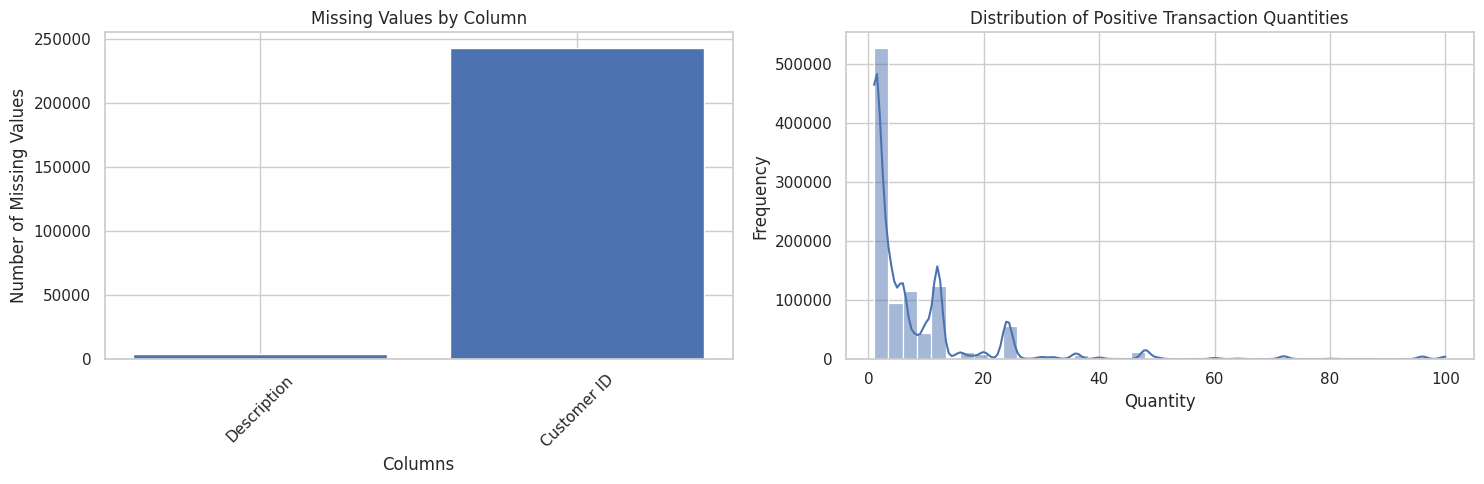

In [6]:
# ==========================================
# CELL 6: INITIAL DATA VISUALISATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Missing values
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

axes[0].bar(
    missing_counts.index,
    missing_counts.values
)

axes[0].set_title("Missing Values by Column")
axes[0].set_xlabel("Columns")
axes[0].set_ylabel("Number of Missing Values")
axes[0].tick_params(axis="x", rotation=45)

# Quantity distribution (limit visual range for readability)
quantity_data = df[
    (df["Quantity"] > 0) &
    (df["Quantity"] <= df["Quantity"].quantile(0.99))
]

sns.histplot(
    quantity_data["Quantity"],
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Positive Transaction Quantities")
axes[1].set_xlabel("Quantity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Use simple visualisations to understand the dataset's missing-value distribution and transaction quantity patterns.

In [7]:
# ==========================================
# CELL 7: INITIAL INSPECTION SUMMARY
# ==========================================

print("=" * 60)
print("ONLINE RETAIL II - INITIAL INSPECTION SUMMARY")
print("=" * 60)

print("\n1. DATASET INFORMATION")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("\n2. TRANSACTION PERIOD")
print("Start Date:", df["InvoiceDate"].min())
print("End Date:", df["InvoiceDate"].max())

print("\n3. BUSINESS INFORMATION")
print("Unique Invoices:", df["Invoice"].nunique())
print("Unique Products:", df["StockCode"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())
print("Countries:", df["Country"].nunique())

print("\n4. DATA QUALITY")
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\n5. UNUSUAL TRANSACTIONS")
print("Negative Quantities:", (df["Quantity"] < 0).sum())
print("Zero Quantities:", (df["Quantity"] == 0).sum())
print("Negative Prices:", (df["Price"] < 0).sum())
print("Zero Prices:", (df["Price"] == 0).sum())
print("Cancelled Invoice Records:", cancelled_count)

print("\n" + "=" * 60)
print("STAGE 1: INITIAL DATA INSPECTION COMPLETED")
print("=" * 60)

ONLINE RETAIL II - INITIAL INSPECTION SUMMARY

1. DATASET INFORMATION
Total Records: 1067371
Total Columns: 8

2. TRANSACTION PERIOD
Start Date: 2009-12-01 07:45:00
End Date: 2011-12-09 12:50:00

3. BUSINESS INFORMATION
Unique Invoices: 53628
Unique Products: 5305
Unique Customers: 5942
Countries: 43

4. DATA QUALITY
Missing Values: 247389
Duplicate Records: 34335

5. UNUSUAL TRANSACTIONS
Negative Quantities: 22950
Zero Quantities: 0
Negative Prices: 5
Zero Prices: 6202
Cancelled Invoice Records: 19494

STAGE 1: INITIAL DATA INSPECTION COMPLETED


Summarise the dataset's key characteristics and document the issues identified during initial inspection.

# Stage 2: Data Cleaning and Preprocessing

In [8]:
# ==========================================
# STAGE 2: DATA CLEANING AND PREPROCESSING
# CELL 1: STANDARDISATION AND MISSING VALUES
# ==========================================

# Create a working copy
df_clean = df.copy()

# Standardise column names
df_clean.columns = df_clean.columns.str.strip()

df_clean.rename(columns={
    "Invoice": "InvoiceNo",
    "Customer ID": "CustomerID",
    "Price": "UnitPrice"
}, inplace=True)

# Convert transaction date
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Convert customer ID to numeric nullable integer
df_clean["CustomerID"] = pd.to_numeric(
    df_clean["CustomerID"],
    errors="coerce"
).astype("Int64")

# Convert quantity and price to numeric
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"],
    errors="coerce"
)

# Standardise text fields
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype("string").str.strip()
df_clean["Description"] = df_clean["Description"].astype("string").str.strip()
df_clean["Country"] = df_clean["Country"].astype("string").str.strip()

# Remove records without essential transaction information
df_clean.dropna(
    subset=[
        "InvoiceNo",
        "InvoiceDate",
        "Quantity",
        "UnitPrice"
    ],
    inplace=True
)

# Remove blank invoice numbers
df_clean = df_clean[
    df_clean["InvoiceNo"] != ""
].copy()

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("COLUMN STANDARDISATION AND CLEANING COMPLETED")
print("-" * 50)

print("Updated columns:")
print(df_clean.columns.tolist())

print("\nMissing values:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

print("\nUpdated dataset shape:", df_clean.shape)
display(df_clean.head())

COLUMN STANDARDISATION AND CLEANING COMPLETED
--------------------------------------------------
Updated columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,243007
Country,0



Updated dataset shape: (1067371, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


Create a working copy, standardise column names, convert variables into appropriate data types and remove records without essential transaction information.

In [9]:
# ==========================================
# CELL 2: DUPLICATE REMOVAL AND CLASSIFICATION
# ==========================================

# Count duplicates before removal
duplicate_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean.drop_duplicates(inplace=True)

# Reset index
df_clean.reset_index(drop=True, inplace=True)

duplicate_after = df_clean.duplicated().sum()

print("DUPLICATE RECORD ANALYSIS")
print("Duplicates before removal:", duplicate_before)
print("Duplicates after removal:", duplicate_after)

# Identify cancelled invoices
df_clean["IsCancelled"] = (
    df_clean["InvoiceNo"]
    .str.startswith("C", na=False)
)

# Identify returned items excluding cancelled invoices
df_clean["IsReturn"] = (
    (df_clean["Quantity"] < 0) &
    (~df_clean["IsCancelled"])
)

# Identify positive quantity records
df_clean["IsPositiveQuantity"] = (
    df_clean["Quantity"] > 0
)

# Create transaction classification summary
transaction_summary = pd.DataFrame({
    "Transaction Type": [
        "Cancelled Invoice Records",
        "Returned Item Records",
        "Positive Quantity Records",
        "Zero Quantity Records"
    ],
    "Number of Records": [
        df_clean["IsCancelled"].sum(),
        df_clean["IsReturn"].sum(),
        df_clean["IsPositiveQuantity"].sum(),
        (df_clean["Quantity"] == 0).sum()
    ]
})

print("\nTRANSACTION CLASSIFICATION")
display(transaction_summary)

# Identify unusual price records
zero_quantity_df = df_clean[
    df_clean["Quantity"] == 0
].copy()

negative_price_df = df_clean[
    df_clean["UnitPrice"] < 0
].copy()

zero_price_df = df_clean[
    df_clean["UnitPrice"] == 0
].copy()

print("\nUNUSUAL TRANSACTION RECORDS")
print("Zero quantity records:", len(zero_quantity_df))
print("Negative price records:", len(negative_price_df))
print("Zero price records:", len(zero_price_df))

# Exclude negative unit prices
df_clean = df_clean[
    df_clean["UnitPrice"] >= 0
].copy()

df_clean.reset_index(drop=True, inplace=True)

print("\nDataset shape after price validation:", df_clean.shape)

DUPLICATE RECORD ANALYSIS
Duplicates before removal: 34335
Duplicates after removal: 0

TRANSACTION CLASSIFICATION


,Transaction Type,Number of Records
0,Cancelled Invoice Records,19104
1,Returned Item Records,3393
2,Positive Quantity Records,1010540
3,Zero Quantity Records,0



UNUSUAL TRANSACTION RECORDS
Zero quantity records: 0
Negative price records: 5
Zero price records: 6014

Dataset shape after price validation: (1033031, 11)


Remove exact duplicate records and distinguish between cancelled invoices, returned items, positive sales and zero-quantity transactions.

In [10]:
# ==========================================
# CELL 3: FEATURE ENGINEERING AND DATASET SEPARATION
# ==========================================

# Calculate revenue for all retained transactions
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Extract date and time features
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["MonthName"] = df_clean["InvoiceDate"].dt.month_name()

df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

df_clean["Day"] = df_clean["InvoiceDate"].dt.day
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

# Create normal sales dataset
sales_df = df_clean[
    (~df_clean["IsCancelled"]) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Create returned items dataset
returns_df = df_clean[
    df_clean["IsReturn"]
].copy()

# Create cancelled transactions dataset
cancelled_df = df_clean[
    df_clean["IsCancelled"]
].copy()

# Reset indexes
sales_df.reset_index(drop=True, inplace=True)
returns_df.reset_index(drop=True, inplace=True)
cancelled_df.reset_index(drop=True, inplace=True)

print("=" * 55)
print("ANALYTICAL DATASET SEPARATION")
print("=" * 55)

print("Cleaned Dataset:", df_clean.shape)
print("Normal Sales Dataset:", sales_df.shape)
print("Returns Dataset:", returns_df.shape)
print("Cancelled Dataset:", cancelled_df.shape)

print("\nSample of normal sales:")
display(sales_df.head())

print("\nSample of returned transactions:")
display(returns_df.head())

ANALYTICAL DATASET SEPARATION
Cleaned Dataset: (1033031, 19)
Normal Sales Dataset: (1007913, 19)
Returns Dataset: (3393, 19)
Cancelled Dataset: (19104, 19)

Sample of normal sales:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsReturn,IsPositiveQuantity,Revenue,Year,Month,MonthName,YearMonth,Day,DayOfWeek,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False,True,83.40,2009,12,December,2009-12,1,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,True,81.00,2009,12,December,2009-12,1,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,True,81.00,2009,12,December,2009-12,1,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False,True,100.80,2009,12,December,2009-12,1,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False,True,30.00,2009,12,December,2009-12,1,Tuesday,7



Sample of returned transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsReturn,IsPositiveQuantity,Revenue,Year,Month,MonthName,YearMonth,Day,DayOfWeek,Hour
0,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,<NA>,United Kingdom,False,True,False,-0.00,2009,12,December,2009-12,1,Tuesday,10
1,489463,71477,short,-240,2009-12-01 10:52:00,0.00,<NA>,United Kingdom,False,True,False,-0.00,2009,12,December,2009-12,1,Tuesday,10
2,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,<NA>,United Kingdom,False,True,False,-0.00,2009,12,December,2009-12,1,Tuesday,10
3,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.00,<NA>,United Kingdom,False,True,False,-0.00,2009,12,December,2009-12,1,Tuesday,11
4,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.00,<NA>,United Kingdom,False,True,False,-0.00,2009,12,December,2009-12,1,Tuesday,17


Calculate transaction revenue, extract date and time information, and create separate datasets for normal sales, returns and cancellations.

In [11]:
# ==========================================
# CELL 4: RETURN VERIFICATION AND AGGREGATION
# ==========================================

# ------------------------------------------
# A. RETURN TRANSACTION VERIFICATION
# ------------------------------------------

print("=" * 55)
print("RETURN TRANSACTION DIAGNOSTICS")
print("=" * 55)

return_value = abs(returns_df["Revenue"].sum())

print("Return records:", len(returns_df))
print("Total returned quantity:", returns_df["Quantity"].sum())

print(
    "Return revenue (signed):",
    f"£{returns_df['Revenue'].sum():,.2f}"
)

print("Recorded return value:", f"£{return_value:,.2f}")

print(
    "Returns with zero unit price:",
    (returns_df["UnitPrice"] == 0).sum()
)

print(
    "Returns with negative unit price:",
    (returns_df["UnitPrice"] < 0).sum()
)

# ------------------------------------------
# B. CUSTOMER-LEVEL ANALYSIS
# ------------------------------------------

customer_df = sales_df[
    sales_df["CustomerID"].notna()
].copy()

customer_summary = customer_df.groupby("CustomerID").agg(
    TotalOrders=("InvoiceNo", "nunique"),
    TotalItems=("Quantity", "sum"),
    TotalSpending=("Revenue", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max")
).reset_index()

print("\nCUSTOMER SUMMARY")
print("Identified customers:", len(customer_summary))
display(customer_summary.head())

# ------------------------------------------
# C. PRODUCT-LEVEL ANALYSIS
# ------------------------------------------

product_df = sales_df[
    sales_df["Description"].notna() &
    (sales_df["Description"].str.strip() != "")
].copy()

product_summary = product_df.groupby(
    ["StockCode", "Description"]
).agg(
    TotalQuantity=("Quantity", "sum"),
    TotalRevenue=("Revenue", "sum"),
    NumberOfTransactions=("InvoiceNo", "nunique")
).reset_index()

product_summary = product_summary.sort_values(
    by="TotalRevenue",
    ascending=False
).reset_index(drop=True)

print("\nPRODUCT SUMMARY")
print("Unique products:", product_summary["StockCode"].nunique())
display(product_summary.head(10))

# ------------------------------------------
# D. MONTHLY SALES ANALYSIS
# ------------------------------------------

monthly_sales = sales_df.groupby("YearMonth").agg(
    TotalRevenue=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
    UniqueCustomers=("CustomerID", "nunique")
).reset_index()

monthly_sales = monthly_sales.sort_values(
    by="YearMonth"
).reset_index(drop=True)

print("\nMONTHLY SALES SUMMARY")
display(monthly_sales.head(12))

# ------------------------------------------
# E. COUNTRY-LEVEL ANALYSIS
# ------------------------------------------

country_sales = sales_df.groupby("Country").agg(
    TotalRevenue=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
    UniqueCustomers=("CustomerID", "nunique")
).reset_index()

country_sales = country_sales.sort_values(
    by="TotalRevenue",
    ascending=False
).reset_index(drop=True)

print("\nCOUNTRY SALES SUMMARY")
display(country_sales.head(10))

RETURN TRANSACTION DIAGNOSTICS
Return records: 3393
Total returned quantity: -569314
Return revenue (signed): £0.00
Recorded return value: £0.00
Returns with zero unit price: 3393
Returns with negative unit price: 0

CUSTOMER SUMMARY
Identified customers: 5878


,CustomerID,TotalOrders,TotalItems,TotalSpending,AverageUnitPrice,FirstPurchase,LastPurchase
0,12346,12,74285,"77,556.46",6.10,2009-12-14 08:34:00,2011-01-18 10:01:00
1,12347,8,2967,"4,921.53",2.50,2010-10-31 14:20:00,2011-12-07 15:52:00
2,12348,5,2714,"2,019.40",3.79,2010-09-27 14:59:00,2011-09-25 13:13:00
3,12349,4,1624,"4,428.69",8.46,2010-04-29 13:20:00,2011-11-21 09:51:00
4,12350,1,197,334.40,3.84,2011-02-02 16:01:00,2011-02-02 16:01:00



PRODUCT SUMMARY
Unique products: 4917


,StockCode,Description,TotalQuantity,TotalRevenue,NumberOfTransactions
0,M,Manual,9629,"339,226.24",784
1,22423,REGENCY CAKESTAND 3 TIER,26478,"330,590.32",3918
2,DOT,DOTCOM POSTAGE,1415,"309,854.11",1415
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94142,"257,546.20",5356
4,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60",1
5,47566,PARTY BUNTING,28200,"148,318.28",2674
6,85099B,JUMBO BAG RED RETROSPOT,77280,"145,961.83",3245
7,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,"129,324.49",2807
8,POST,POSTAGE,5363,"125,682.42",1851
9,22086,PAPER CHAIN KIT 50'S CHRISTMAS,35084,"117,760.29",2018



MONTHLY SALES SUMMARY


,YearMonth,TotalRevenue,TotalQuantity,TotalOrders,UniqueCustomers
0,2009-12,"822,483.95",425461,1682,955
1,2010-01,"651,155.11",390672,1105,720
2,2010-02,"551,504.73",381879,1201,772
3,2010-03,"830,915.26",526026,1681,1057
4,2010-04,"678,875.25",366705,1462,942
5,2010-05,"657,705.50",395868,1500,966
6,2010-06,"749,537.31",406820,1645,1041
7,2010-07,"648,810.27",337895,1529,928
8,2010-08,"695,251.91",472380,1425,911
9,2010-09,"921,696.99",583864,1839,1145



COUNTRY SALES SUMMARY


,Country,TotalRevenue,TotalQuantity,TotalOrders,UniqueCustomers
0,United Kingdom,"17,410,196.12",9187753,36535,5350
1,EIRE,"658,767.31",336329,626,5
2,Netherlands,"554,038.09",383879,228,22
3,Germany,"425,019.71",225154,789,107
4,France,"350,456.09",271901,622,95
5,Australia,"169,283.46",103759,95,15
6,Spain,"108,332.49",50307,154,41
7,Switzerland,"100,685.59",52762,93,22
8,Sweden,"91,869.82",88633,105,19
9,Denmark,"68,580.69",237471,43,12


Investigate the return records and prepare customer, product, monthly and country-level analytical datasets.

In [12]:
# ==========================================
# CELL 5: KPIs, VALIDATION AND EXPORT
# ==========================================

# ------------------------------------------
# A. BUSINESS PERFORMANCE METRICS
# ------------------------------------------

total_revenue = sales_df["Revenue"].sum()
total_quantity = sales_df["Quantity"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_customers = sales_df["CustomerID"].nunique()
total_products = sales_df["StockCode"].nunique()

total_returns = len(returns_df)
total_cancellations = len(cancelled_df)

# Monetary return value is not reliable because all
# identified return records have zero unit prices.
recorded_return_value = abs(returns_df["Revenue"].sum())

kpi_summary = pd.DataFrame({
    "Metric": [
        "Gross Sales Revenue",
        "Total Quantity Sold",
        "Total Orders",
        "Unique Customers",
        "Unique Products",
        "Returned Transactions",
        "Cancelled Invoice Records",
        "Recorded Return Value"
    ],
    "Value": [
        total_revenue,
        total_quantity,
        total_orders,
        total_customers,
        total_products,
        total_returns,
        total_cancellations,
        recorded_return_value
    ]
})

print("BUSINESS PERFORMANCE METRICS")
display(kpi_summary)

# ------------------------------------------
# B. FINAL DATA VALIDATION
# ------------------------------------------

validation_results = {
    "Total Sales Records": len(sales_df),
    "Duplicate Sales Records": sales_df.duplicated().sum(),
    "Missing Invoice Numbers": sales_df["InvoiceNo"].isnull().sum(),
    "Missing Invoice Dates": sales_df["InvoiceDate"].isnull().sum(),
    "Missing Product Descriptions": sales_df["Description"].isnull().sum(),
    "Missing Customer IDs": sales_df["CustomerID"].isnull().sum(),
    "Cancelled Invoices in Sales": sales_df["IsCancelled"].sum(),
    "Non-positive Quantities": (sales_df["Quantity"] <= 0).sum(),
    "Non-positive Prices": (sales_df["UnitPrice"] <= 0).sum(),
    "Negative Revenue Records": (sales_df["Revenue"] < 0).sum(),
    "Return Records": len(returns_df),
    "Returns with Zero Unit Price": (returns_df["UnitPrice"] == 0).sum(),
    "Returns with Negative Revenue": (returns_df["Revenue"] < 0).sum()
}

validation_df = pd.DataFrame(
    list(validation_results.items()),
    columns=["Validation Check", "Result"]
)

print("\nFINAL DATA VALIDATION")
display(validation_df)

# ------------------------------------------
# C. EXPORT PROCESSED DATASETS
# ------------------------------------------

os.makedirs("data/processed", exist_ok=True)

export_datasets = {
    "cleaned_transactions.csv": df_clean,
    "sales_data.csv": sales_df,
    "returns_data.csv": returns_df,
    "cancelled_transactions.csv": cancelled_df,
    "customer_summary.csv": customer_summary,
    "product_summary.csv": product_summary,
    "monthly_sales.csv": monthly_sales,
    "country_sales.csv": country_sales,
    "kpi_summary.csv": kpi_summary
}

for filename, dataset in export_datasets.items():
    dataset.to_csv(
        f"data/processed/{filename}",
        index=False
    )

print("\nPROCESSED DATASETS EXPORTED")
for filename in export_datasets:
    print("✓", filename)

# ------------------------------------------
# D. FINAL PREPROCESSING SUMMARY
# ------------------------------------------

print("\n" + "=" * 60)
print("ONLINE RETAIL II - DATA PREPROCESSING SUMMARY")
print("=" * 60)

print("\n1. ORIGINAL DATASET")
print("Records:", len(df))
print("Columns:", len(df.columns))

print("\n2. CLEANED DATASET")
print("Records:", len(df_clean))
print("Columns:", len(df_clean.columns))

print("\n3. ANALYTICAL DATASETS")
print("Sales Records:", len(sales_df))
print("Return Records:", len(returns_df))
print("Cancelled Records:", len(cancelled_df))

print("\n4. AGGREGATED DATASETS")
print("Customer Records:", len(customer_summary))
print("Product Records:", len(product_summary))
print("Monthly Records:", len(monthly_sales))
print("Country Records:", len(country_sales))

print("\n5. BUSINESS PERFORMANCE")
print(f"Gross Sales Revenue: £{total_revenue:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Returned Transactions: {total_returns:,}")
print(f"Cancelled Records: {total_cancellations:,}")

print("\n6. RETURN DATA LIMITATION")
print("All identified return records have zero unit prices.")
print("A reliable monetary return value cannot be estimated.")

print("\n" + "=" * 60)
print("STAGE 2: DATA PREPROCESSING COMPLETED")
print("=" * 60)

BUSINESS PERFORMANCE METRICS


,Metric,Value
0,Gross Sales Revenue,"20,476,260.45"
1,Total Quantity Sold,"11,205,148.00"
2,Total Orders,"40,077.00"
3,Unique Customers,"5,878.00"
4,Unique Products,"4,917.00"
5,Returned Transactions,"3,393.00"
6,Cancelled Invoice Records,"19,104.00"
7,Recorded Return Value,0.00



FINAL DATA VALIDATION


,Validation Check,Result
0,Total Sales Records,1007913
1,Duplicate Sales Records,0
2,Missing Invoice Numbers,0
3,Missing Invoice Dates,0
4,Missing Product Descriptions,0
5,Missing Customer IDs,228488
6,Cancelled Invoices in Sales,0
7,Non-positive Quantities,0
8,Non-positive Prices,0
9,Negative Revenue Records,0



PROCESSED DATASETS EXPORTED
✓ cleaned_transactions.csv
✓ sales_data.csv
✓ returns_data.csv
✓ cancelled_transactions.csv
✓ customer_summary.csv
✓ product_summary.csv
✓ monthly_sales.csv
✓ country_sales.csv
✓ kpi_summary.csv

ONLINE RETAIL II - DATA PREPROCESSING SUMMARY

1. ORIGINAL DATASET
Records: 1067371
Columns: 8

2. CLEANED DATASET
Records: 1033031
Columns: 19

3. ANALYTICAL DATASETS
Sales Records: 1007913
Return Records: 3393
Cancelled Records: 19104

4. AGGREGATED DATASETS
Customer Records: 5878
Product Records: 5601
Monthly Records: 25
Country Records: 43

5. BUSINESS PERFORMANCE
Gross Sales Revenue: £20,476,260.45
Total Quantity Sold: 11,205,148
Total Orders: 40,077
Unique Customers: 5,878
Unique Products: 4,917
Returned Transactions: 3,393
Cancelled Records: 19,104

6. RETURN DATA LIMITATION
All identified return records have zero unit prices.
A reliable monetary return value cannot be estimated.

STAGE 2: DATA PREPROCESSING COMPLETED


Calculate overall sales performance, perform final quality checks and export all processed datasets for future analysis.

##Stage 3 – Exploratory Data Analysis and Visualisation

In [13]:
# STAGE 3: PREPARE DATA FOR VISUALISATION

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np

# Prepare sales data
eda_sales = sales_df.copy()

# Create order-level summary
order_summary = (
    eda_sales.groupby("InvoiceNo")
    .agg(
        OrderValue=("Revenue", "sum"),
        OrderDate=("InvoiceDate", "min"),
        CustomerID=("CustomerID", "first"),
        Country=("Country", "first")
    )
    .reset_index()
)

# Create customer-level summary
customer_analysis = (
    eda_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        TotalOrders=("InvoiceNo", "nunique"),
        TotalSpending=("Revenue", "sum"),
        TotalItems=("Quantity", "sum")
    )
    .reset_index()
)

# Prepare monthly data
monthly_analysis = monthly_sales.copy()
monthly_analysis["YearMonth"] = pd.to_datetime(
    monthly_analysis["YearMonth"]
)

# Prepare country data
country_analysis = country_sales.copy()

# Prepare day and hour data
eda_sales["DayOfWeek"] = pd.Categorical(
    eda_sales["DayOfWeek"],
    categories=[
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ],
    ordered=True
)

print("Order summary:", order_summary.shape)
print("Customer analysis:", customer_analysis.shape)
print("Monthly analysis:", monthly_analysis.shape)
print("Country analysis:", country_analysis.shape)

Order summary: (40077, 5)
Customer analysis: (5878, 4)
Monthly analysis: (25, 5)
Country analysis: (43, 5)


This cell prepares the order-level and customer-level datasets needed for the charts.

In [14]:
# KPI INDICATORS

gross_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
unique_customers = sales_df["CustomerID"].nunique()
unique_products = sales_df["StockCode"].nunique()

fig_kpi = make_subplots(
    rows=1,
    cols=4,
    specs=[[{"type": "indicator"}] * 4]
)

kpi_values = [
    ("Gross Revenue", gross_revenue, "£", ",.0f"),
    ("Total Orders", total_orders, "", ",.0f"),
    ("Unique Customers", unique_customers, "", ",.0f"),
    ("Unique Products", unique_products, "", ",.0f")
]

for col, (label, value, prefix, fmt) in enumerate(kpi_values, start=1):
    fig_kpi.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label},
            number={
                "prefix": prefix,
                "valueformat": fmt,
                "font": {"size": 25}
            }
        ),
        row=1,
        col=col
    )

fig_kpi.update_layout(
    title="Overall Business Performance",
    height=220,
    template="plotly_white",
    margin=dict(t=65, b=20, l=20, r=20)
)

fig_kpi.show()

These indicators provide a quick overview of the overall business performance.

In [15]:
# CHART 1: MONTHLY REVENUE - LINE CHART

fig1 = px.line(
    monthly_analysis,
    x="YearMonth",
    y="TotalRevenue",
    markers=True,
    title="Monthly Revenue Trend",
    labels={
        "YearMonth": "Month",
        "TotalRevenue": "Revenue (£)"
    }
)

fig1.update_traces(line=dict(width=3))
fig1.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=450
)

fig1.show()


# CHART 2: MONTHLY ORDERS - BAR CHART

fig2 = px.bar(
    monthly_analysis,
    x="YearMonth",
    y="TotalOrders",
    title="Monthly Order Volume",
    labels={
        "YearMonth": "Month",
        "TotalOrders": "Number of Orders"
    }
)

fig2.update_layout(
    template="plotly_white",
    xaxis_tickangle=-45,
    height=450
)

fig2.show()

The line chart identifies revenue trends over time. The bar chart compares the number of orders across months.

In [16]:
# CHART 3: ORDER VALUE DISTRIBUTION - HISTOGRAM

order_value_limit = order_summary["OrderValue"].quantile(0.99)

order_display = order_summary[
    order_summary["OrderValue"] <= order_value_limit
]

fig3 = px.histogram(
    order_display,
    x="OrderValue",
    nbins=50,
    title="Distribution of Order Values",
    labels={"OrderValue": "Order Value (£)"},
    marginal="box"
)

fig3.update_layout(
    template="plotly_white",
    height=450
)

fig3.show()

This histogram shows how order values are distributed. To keep the main pattern readable, I will limit the displayed range to the 99th percentile. The original data remains unchanged.

In [17]:
# CHART 4: CUSTOMER FREQUENCY VS SPENDING - SCATTER PLOT

fig4 = px.scatter(
    customer_analysis,
    x="TotalOrders",
    y="TotalSpending",
    size="TotalItems",
    hover_name="CustomerID",
    title="Customer Purchase Frequency vs Spending",
    labels={
        "TotalOrders": "Number of Orders",
        "TotalSpending": "Total Spending (£)",
        "TotalItems": "Total Items Purchased"
    },
    opacity=0.65
)

fig4.update_layout(
    template="plotly_white",
    height=500
)

fig4.show()

This scatter plot compares how frequently customers place orders with how much they spend. Each point represents one customer.

In [18]:
# CHART 5: COUNTRY CONTRIBUTION - TREEMAP

fig5 = px.treemap(
    country_analysis,
    path=["Country"],
    values="TotalRevenue",
    title="Revenue Contribution by Country",
    color="TotalRevenue",
    color_continuous_scale="Blues"
)

fig5.update_layout(
    template="plotly_white",
    height=550
)

fig5.show()

The treemap compares the revenue contribution of different countries. Larger rectangles represent countries with higher revenue.

In [19]:
# CHART 6: DAY AND HOUR PURCHASING PATTERNS - HEATMAP

purchase_activity = (
    eda_sales.groupby(["DayOfWeek", "Hour"], observed=False)["InvoiceNo"]
    .nunique()
    .reset_index(name="NumberOfOrders")
)

heatmap_data = purchase_activity.pivot(
    index="DayOfWeek",
    columns="Hour",
    values="NumberOfOrders"
).fillna(0)

fig6 = px.imshow(
    heatmap_data,
    labels={
        "x": "Hour of Day",
        "y": "Day of Week",
        "color": "Number of Orders"
    },
    title="Purchasing Activity by Day and Hour",
    color_continuous_scale="Blues",
    aspect="auto"
)

fig6.update_layout(
    template="plotly_white",
    height=450
)

fig6.show()

This heatmap identifies the days and hours when customers place orders. Darker or more intense cells indicate higher order activity.

In [20]:
# EDA FINDINGS SUMMARY

best_month = monthly_analysis.loc[
    monthly_analysis["TotalRevenue"].idxmax()
]

best_country = country_analysis.loc[
    country_analysis["TotalRevenue"].idxmax()
]

average_order_value = order_summary["OrderValue"].mean()
median_order_value = order_summary["OrderValue"].median()

print("=" * 55)
print("EXPLORATORY DATA ANALYSIS - KEY FINDINGS")
print("=" * 55)

print(f"\nHighest Revenue Month: {best_month['YearMonth'].strftime('%B %Y')}")
print(f"Revenue: £{best_month['TotalRevenue']:,.2f}")

print(f"\nTop Revenue-Contributing Country: {best_country['Country']}")
print(f"Revenue: £{best_country['TotalRevenue']:,.2f}")

print(f"\nAverage Order Value: £{average_order_value:,.2f}")
print(f"Median Order Value: £{median_order_value:,.2f}")

print(f"\nNumber of Customers Analysed: {len(customer_analysis):,}")
print(f"Number of Orders Analysed: {len(order_summary):,}")

print("\nEDA visualisations completed successfully.")

EXPLORATORY DATA ANALYSIS - KEY FINDINGS

Highest Revenue Month: November 2011
Revenue: £1,503,866.78

Top Revenue-Contributing Country: United Kingdom
Revenue: £17,410,196.12

Average Order Value: £510.92
Median Order Value: £302.22

Number of Customers Analysed: 5,878
Number of Orders Analysed: 40,077

EDA visualisations completed successfully.


##Stage 4 – Build the Interactive Online Retail II Dashboard

In [21]:
# DASHBOARD MONTHLY REVENUE CHART WITH YEAR SELECTOR

import plotly.graph_objects as go

monthly_dashboard_data = monthly_analysis.copy()
monthly_dashboard_data["Year"] = monthly_dashboard_data["YearMonth"].dt.year

available_years = sorted(monthly_dashboard_data["Year"].unique())

dashboard_revenue_fig = go.Figure()

# Add a separate trace for each year
for year in available_years:
    year_data = monthly_dashboard_data[
        monthly_dashboard_data["Year"] == year
    ]

    dashboard_revenue_fig.add_trace(
        go.Scatter(
            x=year_data["YearMonth"],
            y=year_data["TotalRevenue"],
            mode="lines+markers",
            name=str(year),
            visible=True
        )
    )

# Create dropdown options
dropdown_buttons = [
    dict(
        label="All Years",
        method="update",
        args=[
            {"visible": [True] * len(available_years)},
            {"title": "Monthly Revenue Trend – All Years"}
        ]
    )
]

for selected_year in available_years:
    visibility = [year == selected_year for year in available_years]

    dropdown_buttons.append(
        dict(
            label=str(selected_year),
            method="update",
            args=[
                {"visible": visibility},
                {"title": f"Monthly Revenue Trend – {selected_year}"}
            ]
        )
    )

dashboard_revenue_fig.update_layout(
    title="Monthly Revenue Trend – All Years",
    xaxis_title="Month",
    yaxis_title="Revenue (£)",
    template="plotly_white",
    height=420,
    hovermode="x unified",
    updatemenus=[
        dict(
            buttons=dropdown_buttons,
            direction="down",
            x=1,
            xanchor="right",
            y=1.18,
            yanchor="top"
        )
    ],
    margin=dict(t=100, l=60, r=30, b=60)
)

dashboard_revenue_fig.show()

I will add a year selector so that the viewer can display all months or focus on 2010 or 2011.

In [22]:
# STAGE 4: BUILD AND EXPORT THE INTERACTIVE DASHBOARD

import plotly.io as pio
from IPython.display import display, HTML
from google.colab import files
from datetime import datetime

# Calculate KPI values
gross_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
unique_customers = sales_df["CustomerID"].nunique()
unique_products = sales_df["StockCode"].nunique()

# Prepare chart list
dashboard_charts = [
    ("Monthly Revenue Trend", dashboard_revenue_fig),
    ("Monthly Order Volume", fig2),
    ("Distribution of Order Values", fig3),
    ("Customer Purchase Frequency vs Spending", fig4),
    ("Revenue Contribution by Country", fig5),
    ("Purchasing Activity by Day and Hour", fig6)
]

# Convert charts into HTML
chart_html = []

for index, (chart_title, chart) in enumerate(dashboard_charts):

    chart_fragment = pio.to_html(
        chart,
        full_html=False,
        include_plotlyjs="cdn" if index == 0 else False,
        config={
            "responsive": True,
            "displaylogo": False,
            "scrollZoom": True
        }
    )

    chart_html.append(f"""
        <section class="chart-card">
            {chart_fragment}
        </section>
    """)

# Create KPI cards
kpi_html = f"""
<div class="kpi-grid">

    <div class="kpi-card">
        <p>Gross Revenue</p>
        <h2>£{gross_revenue:,.2f}</h2>
    </div>

    <div class="kpi-card">
        <p>Total Orders</p>
        <h2>{total_orders:,}</h2>
    </div>

    <div class="kpi-card">
        <p>Unique Customers</p>
        <h2>{unique_customers:,}</h2>
    </div>

    <div class="kpi-card">
        <p>Unique Products</p>
        <h2>{unique_products:,}</h2>
    </div>

</div>
"""

# Build complete dashboard
dashboard_html = f"""
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">

    <title>Online Retail II Sales Dashboard</title>

    <style>

        * {{
            box-sizing: border-box;
        }}

        body {{
            margin: 0;
            padding: 25px;
            background: #f4f6fb;
            color: #26344a;
            font-family: Arial, sans-serif;
        }}

        .dashboard-container {{
            max-width: 1500px;
            margin: auto;
        }}

        .header {{
            background: #172b4d;
            color: white;
            padding: 28px;
            border-radius: 12px;
            margin-bottom: 25px;
        }}

        .header h1 {{
            margin: 0 0 10px 0;
            font-size: 28px;
        }}

        .header p {{
            margin: 0;
            color: #dce5f5;
        }}

        .kpi-grid {{
            display: grid;
            grid-template-columns: repeat(4, 1fr);
            gap: 18px;
            margin-bottom: 25px;
        }}

        .kpi-card {{
            background: white;
            padding: 22px;
            border-radius: 10px;
            box-shadow: 0 2px 8px rgba(0,0,0,0.06);
            border-left: 5px solid #526dff;
        }}

        .kpi-card p {{
            color: #68758a;
            margin: 0 0 12px 0;
            font-size: 14px;
        }}

        .kpi-card h2 {{
            margin: 0;
            font-size: 25px;
            color: #172b4d;
        }}

        .chart-grid {{
            display: grid;
            grid-template-columns: repeat(2, minmax(0, 1fr));
            gap: 20px;
        }}

        .chart-card {{
            background: white;
            padding: 12px;
            border-radius: 10px;
            box-shadow: 0 2px 8px rgba(0,0,0,0.06);
            min-width: 0;
        }}

        .footer {{
            text-align: center;
            color: #718096;
            font-size: 13px;
            padding: 25px 0 5px;
        }}

        @media (max-width: 900px) {{
            .kpi-grid {{
                grid-template-columns: repeat(2, 1fr);
            }}

            .chart-grid {{
                grid-template-columns: 1fr;
            }}
        }}

        @media (max-width: 500px) {{
            body {{
                padding: 12px;
            }}

            .kpi-grid {{
                grid-template-columns: 1fr;
            }}
        }}

    </style>
</head>

<body>

<div class="dashboard-container">

    <div class="header">
        <h1>Online Retail II Sales Dashboard</h1>
        <p>
            An interactive analysis of sales performance,
            customer behaviour and purchasing patterns
            from December 2009 to December 2011.
        </p>
    </div>

    {kpi_html}

    <div class="chart-grid">
        {''.join(chart_html)}
    </div>

    <div class="footer">
        <p>Online Retail II Dataset | Data Analytics Project</p>
        <p>Dashboard generated using Python, Pandas and Plotly</p>
    </div>

</div>

</body>
</html>
"""

# Save HTML file
dashboard_path = "/content/online_retail_II_dashboard.html"

with open(dashboard_path, "w", encoding="utf-8") as file:
    file.write(dashboard_html)

print("Dashboard created successfully!")
print("File location:", dashboard_path)
print("Number of visualisations:", len(dashboard_charts))
print("Number of KPI indicators: 4")

# Display dashboard inside Colab
display(HTML(dashboard_html))

# Download dashboard
files.download(dashboard_path)

Dashboard created successfully!
File location: /content/online_retail_II_dashboard.html
Number of visualisations: 6
Number of KPI indicators: 4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

This cell arranges the KPI cards and six charts into a single dashboard page. The Plotly charts retain their hover, zoom, pan, and toolbar features.

## Project Summary

This project analyses the Online Retail II dataset using Python.

- Cleaned and prepared the retail transaction data.
- Analysed sales, customers, and purchasing patterns.
- Created four KPI indicators.
- Developed six interactive visualisations using Plotly.
- Built an interactive dashboard and exported it as an HTML file.

**Tools Used:** Python, Pandas, NumPy, Plotly and Google Colab.

**Outcome:** An interactive sales dashboard that helps understand business performance and customer purchasing behaviour.